**Statistical Arbitrage & Pairs Trading Engine**

Facundo Urquizo

_Statistics and Quantitative Modeling - Data Science_


[*********************100%***********************]  2 of 2 completed


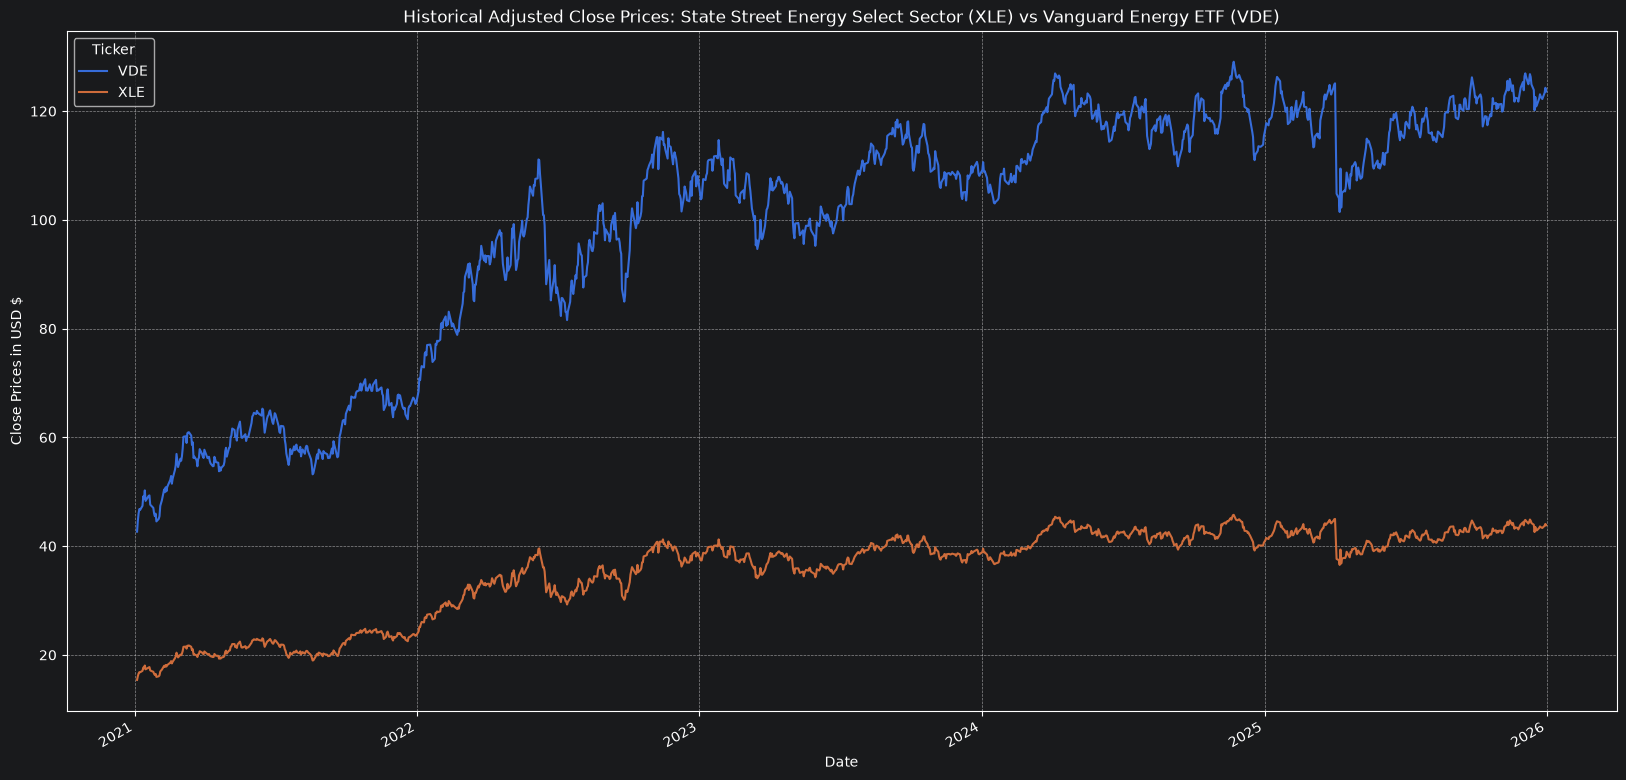

In [5]:
import yfinance as yf
import datetime
import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.regression.linear_model import OLS
from statsmodels.tools import add_constant
from statsmodels.tsa.stattools import coint
import numpy as np

#Definition of classic cointegrated equity pairs
assets = ['XLE', 'VDE']
start_date = datetime.datetime(2021, 1, 1)
end_date = datetime.datetime(2026, 1, 1)

#Retrieve adjusted prices of the selected assets from Yahoo Finance
data = yf.download(assets, start_date, end_date, auto_adjust=True)

#Select the 'Close' column from prices
close_data = data['Close']

#Remove rows with missing values from the table completely
close_data.dropna(inplace=True)

#Plot historical price series (line graph)
close_data.plot(figsize=(20,10),title='Historical Adjusted Close Prices: State Street Energy Select Sector (XLE) vs Vanguard Energy ETF (VDE)')
plt.ylabel('Close Prices in USD $')
plt.grid(True, color='white', linestyle='--', alpha=0.5)
plt.show()

Cointegrated
Hedge Ratio (Beta): 0.3564
Mean spread: -0.013905


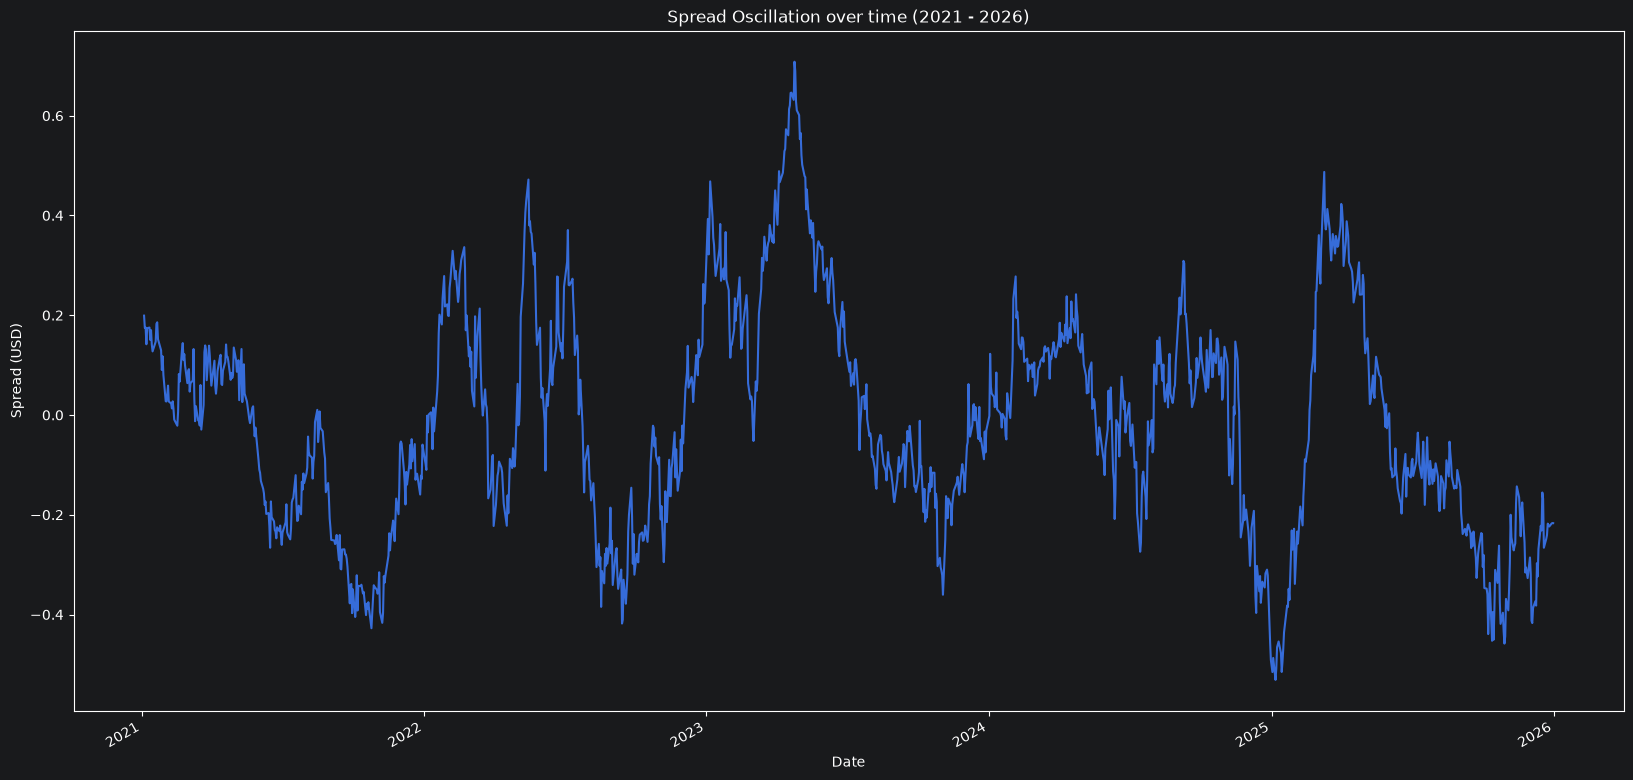

In [6]:
#Separating two price vectors:
series_1 = close_data['XLE']
series_2 = close_data['VDE']

#Evaluate their cointegration based on p value:
cointegration_test = coint(series_1, series_2).pvalue
if cointegration_test <0.05:
    print('Cointegrated')
else:
    print('Not Cointegrated')

#Calculating the hedge ratio (B = Beta x A + Alpha)
#1. Calculate dependent and independent variables: B = XLE; A=VDE
B = series_1
A = series_2
#2 Add constant (Alpha) to A
A_with_constant = add_constant(A)
#3. Fit an OLS Regression algorithm
Ordinary_least_squares = OLS(B, A_with_constant).fit()
#4. Extract the coefficient (Hedge Ratio) and save it in a variable
beta = Ordinary_least_squares.params['VDE']
#5. Construct the spread (it uses constant at its average level)
#Beta scales with price but the intercept adds a fixed dollar amount
spread = B - (beta * series_2)
print(f"Hedge Ratio (Beta): {beta:.4f}")
#Display the spread mean
print(f"Mean spread: {spread.mean():.6f}")
#Display the spread plot
spread.plot(figsize=(20,10), xlabel='Date', ylabel='Spread (USD)', title='Spread Oscillation over time (2021 - 2026)')
plt.show()


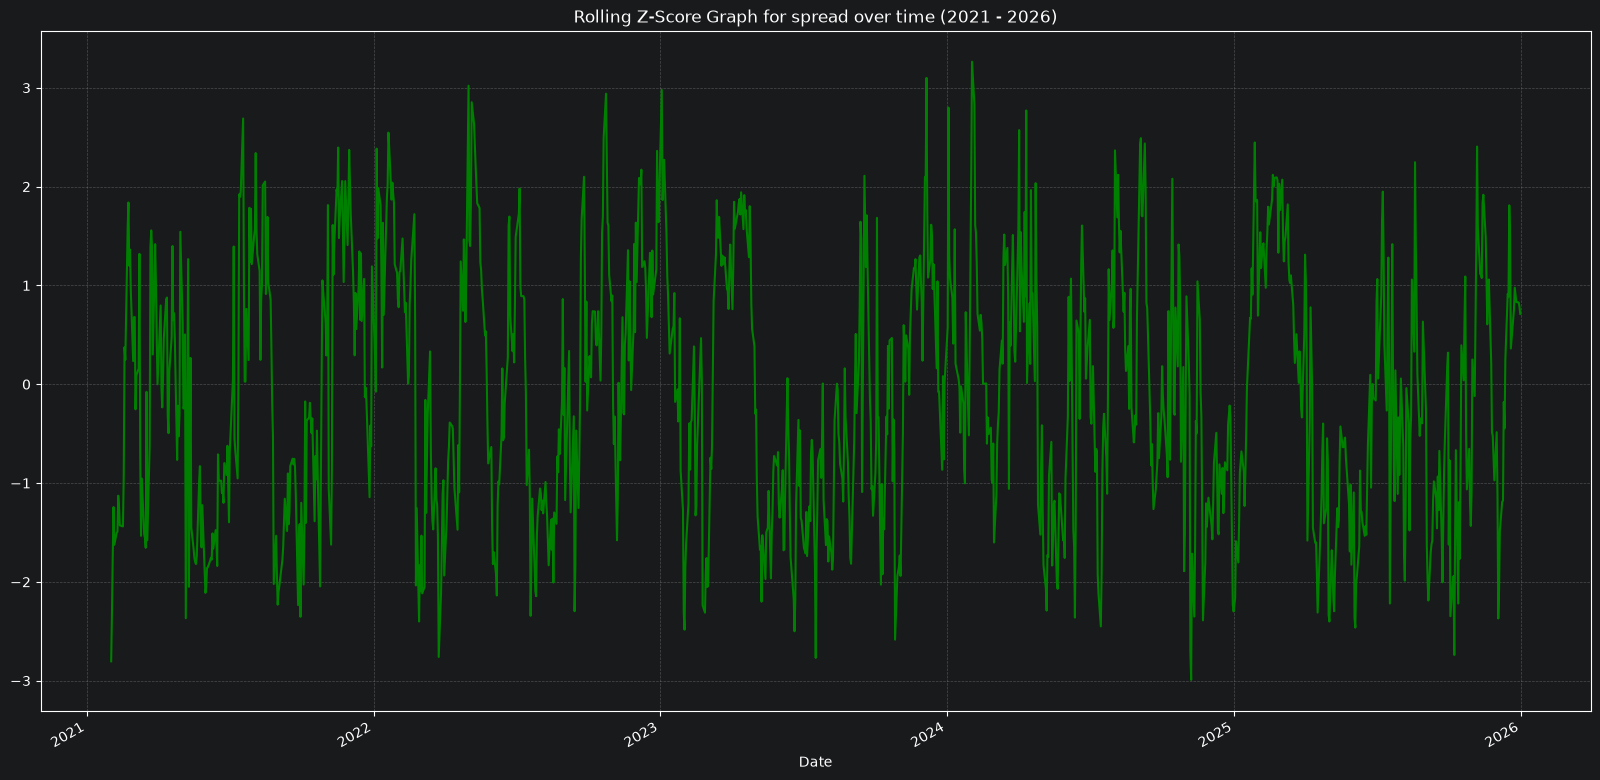

In [7]:
#Rolling Z score (How many standard deviations is the last spread from the mean spread)
rolling_mean = spread.rolling(window=20).mean()
rolling_std =spread.rolling(window=20).std()
rolling_z_score = (spread-rolling_mean)/rolling_std
rolling_z_score_without_NaaNs = rolling_z_score.dropna()
rolling_z_score_without_NaaNs.plot(figsize=(20,10), title='Rolling Z-Score Graph for spread over time (2021 - 2026)', color='green')
plt.grid(True, color='grey', linestyle='--', alpha=0.5)
plt.show()

In [8]:
#Discrete Trading Signals: When to choose whether to Buy (-1), Hold (0) or Sell (1)
conditions = [rolling_z_score_without_NaaNs >2.0, rolling_z_score_without_NaaNs <-2.0,(rolling_z_score_without_NaaNs < 0.05) & (rolling_z_score_without_NaaNs > -0.05)]
choices = [-1,1,0]
signals = np.select(conditions, choices,default=np.nan)
#Creating a Series with signals and dates
signals_series = pd.Series(signals, index=rolling_z_score_without_NaaNs.index)
#Defined the positions (holding state) (short, exit, or long) based on signals and used ffill to drag the last value when there's no new value. Pushed  positions forward by one day so that today’s closing signal becomes tomorrow’s actual trading position
positions = signals_series.ffill().shift(1)
print(positions)

Date
2021-02-01    1.0
2021-02-02    1.0
2021-02-03    1.0
2021-02-04    1.0
2021-02-05    1.0
             ... 
2025-12-24    1.0
2025-12-26    1.0
2025-12-29    1.0
2025-12-30    1.0
2025-12-31    1.0
Length: 1236, dtype: float64


In [12]:
#Returns Calculation
#Calculate how much prices changed each day in terms of percentage
xle_returns = series_1.pct_change()
vde_returns = series_2.pct_change()
#Calculate the daily return of the spread based on hedge ratio
spread_returns = xle_returns -(beta*vde_returns)
#Calculate the strategy returns by multiplying by day in the selected timeframe:
strategy_returns = positions*spread_returns
print(strategy_returns)


Date
2021-01-04         NaN
2021-01-05         NaN
2021-01-06         NaN
2021-01-07         NaN
2021-01-08         NaN
                ...   
2025-12-24   -0.001699
2025-12-26   -0.002520
2025-12-29    0.006182
2025-12-30    0.004926
2025-12-31   -0.003590
Length: 1255, dtype: float64


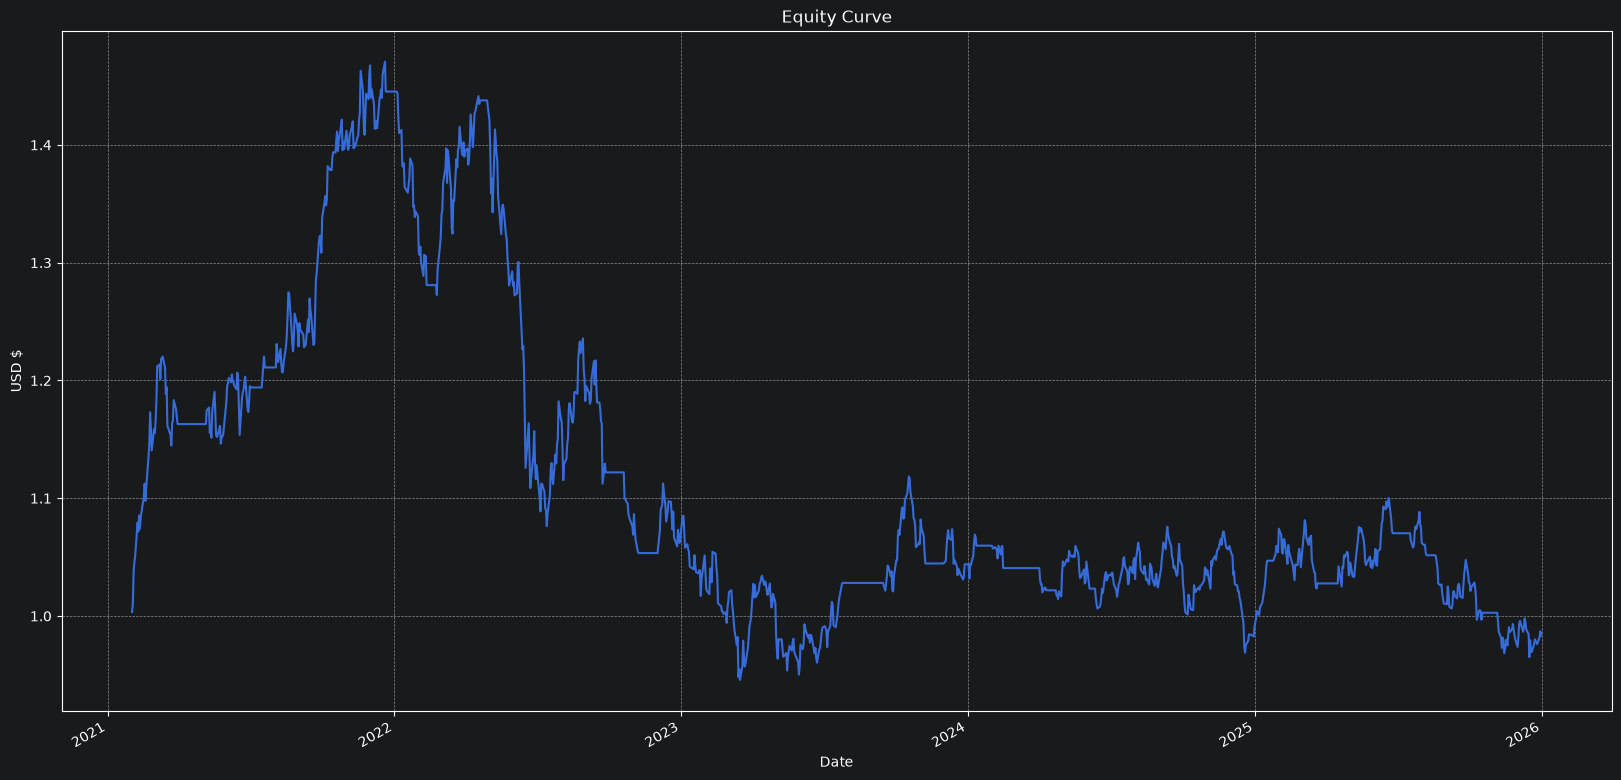

In [13]:
# Performance evaluation: Calculate the compound growth over time
#Added 1 to multiply by cumprod(), which multiplies percentage changes chronologically
equity_curve = (strategy_returns+1).cumprod()
equity_curve.plot(figsize=(20,10), title='Equity Curve')
plt.ylabel('USD $')
plt.grid(True, color='white', linestyle='--', alpha=0.5)
plt.show()

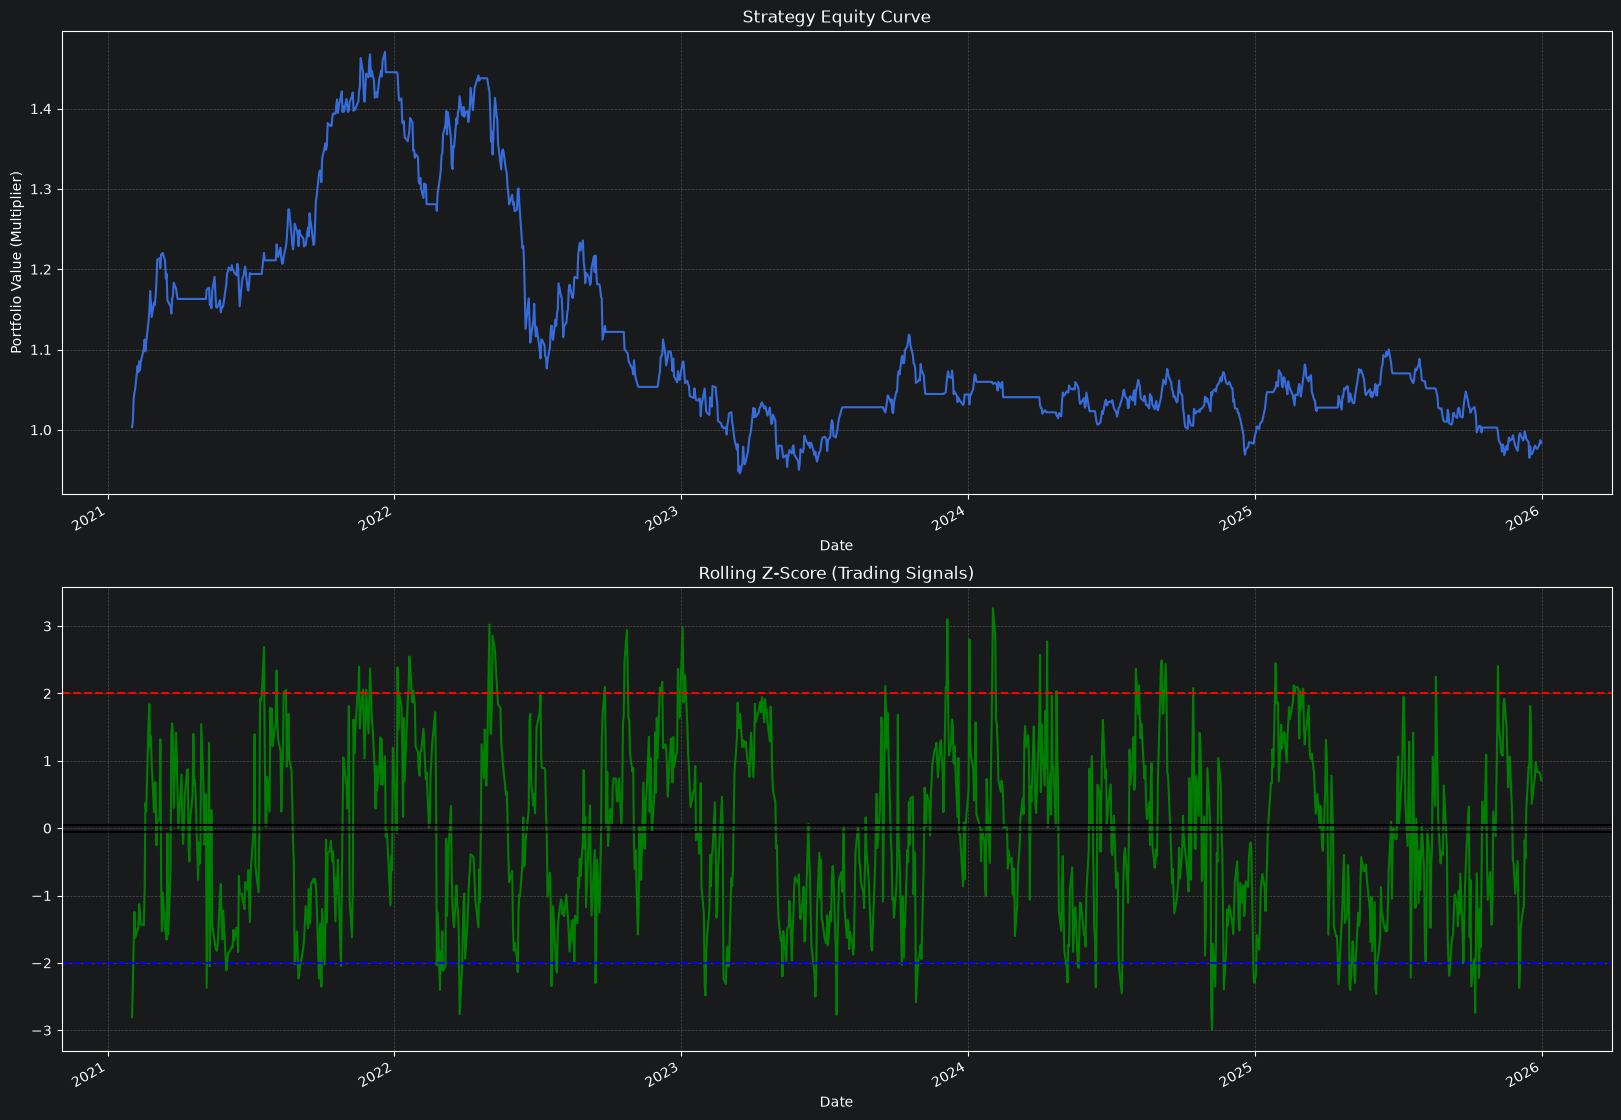

In [16]:
#Visualize rolling_z_score and equity_curve together
#Using subplots to compare the two different variables
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(20, 15))

# Plotting Equity Curve or Portfolio Value Chart
equity_curve.plot(ax=ax1, title='Strategy Equity Curve')
ax1.set_ylabel('Portfolio Value (Multiplier)')
ax1.grid(True, color='grey', linestyle='--', alpha=0.5)

# Plotting Z-Score & Tripwires indicating signals
rolling_z_score_without_NaaNs.plot(ax=ax2, title='Rolling Z-Score (Trading Signals)', color='green')
# Short Signal - Red (-1), Long Signal - Blue (+1), Exit Zone - Black (0.5)(-0.05)
ax2.axhline(y=2.0, color='red', linestyle='--')
ax2.axhline(y=-2.0, color='blue', linestyle='--')
ax2.axhline(y=0.05, color='black', linestyle='-')
ax2.axhline(y=-0.05, color='black', linestyle='-')
ax2.grid(True, color='grey', linestyle='--', alpha=0.5)
plt.show()